# Semantic segmentation of Mitochondria using U-Net

## Data loading

In [1]:
!wget -O training.tif "https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/training.tif"
!wget -O training_groundtruth.tif "https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/training_groundtruth.tif"
!wget -O testing.tif "https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/testing.tif"
!wget -O testing_groundtruth.tif "https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/testing_groundtruth.tif"

--2026-11-10 16:37:32--  https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/training.tif
Resolving documents.epfl.ch (documents.epfl.ch)... 128.178.211.3, 2001:620:618:1d3:7:80b2:d301:1b
Connecting to documents.epfl.ch (documents.epfl.ch)|128.178.211.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 129919357 (124M) [image/tiff]
Saving to: ‘training.tif’

training.tif        100%[===================>] 123.90M  12.8MB/s    in 10s     

2026-11-10 16:37:43 (12.3 MB/s) - ‘training.tif’ saved [129919357/129919357]

--2026-11-10 16:37:44--  https://documents.epfl.ch/groups/c/cv/cvlab-unit/www/data/%20ElectronMicroscopy_Hippocampus/training_groundtruth.tif
Resolving documents.epfl.ch (documents.epfl.ch)... 128.178.211.3, 2001:620:618:1d3:7:80b2:d301:1b
Connecting to documents.epfl.ch (documents.epfl.ch)|128.178.211.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 129919357 (124M) [image/tiff]
Saving

In [2]:
!pip install tifffile matplotlib opencv-python

In [3]:
import tifffile
import os
from PIL import Image

image_path = '/content/training.tif'
mask_path = '/content/training_groundtruth.tif'

os.makedirs('/content/dataset/images', exist_ok=True)
os.makedirs('/content/dataset/masks', exist_ok=True)

with tifffile.TiffFile(image_path) as img_tif, \
     tifffile.TiffFile(mask_path) as mask_tif:

    print("Image slices:", len(img_tif.pages))
    print("Mask slices:", len(mask_tif.pages))

    assert len(img_tif.pages) == len(mask_tif.pages)

    for i, (img_page, mask_page) in enumerate(
        zip(img_tif.pages, mask_tif.pages)
    ):
        img = img_page.asarray()
        mask = mask_page.asarray()

        Image.fromarray(img).save(
            f'/content/dataset/images/{i:04d}.png'
        )

        Image.fromarray(mask).save(
            f'/content/dataset/masks/{i:04d}.png'
        )

print("Extraction complete!")

Image slices: 165
Mask slices: 165
Extraction complete!


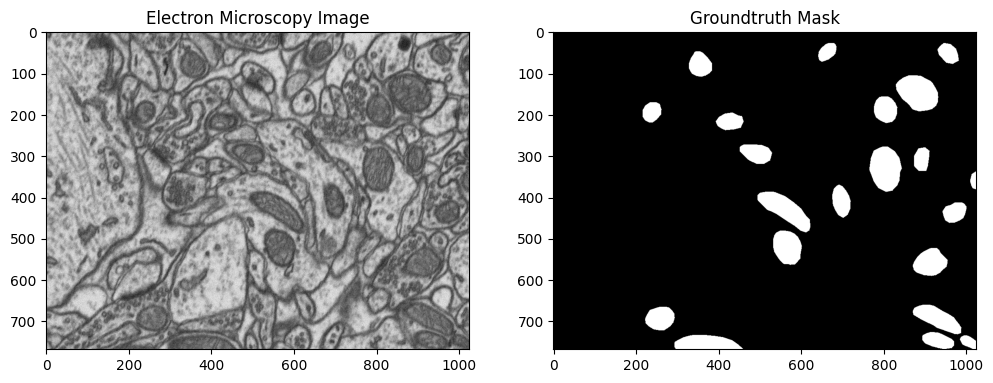

In [4]:
# sample image
import matplotlib.pyplot as plt

img = tifffile.imread(image_path, key=50)
mask = tifffile.imread(mask_path, key=50)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Electron Microscopy Image')

ax[1].imshow(mask, cmap='gray')
ax[1].set_title('Groundtruth Mask')

plt.show()

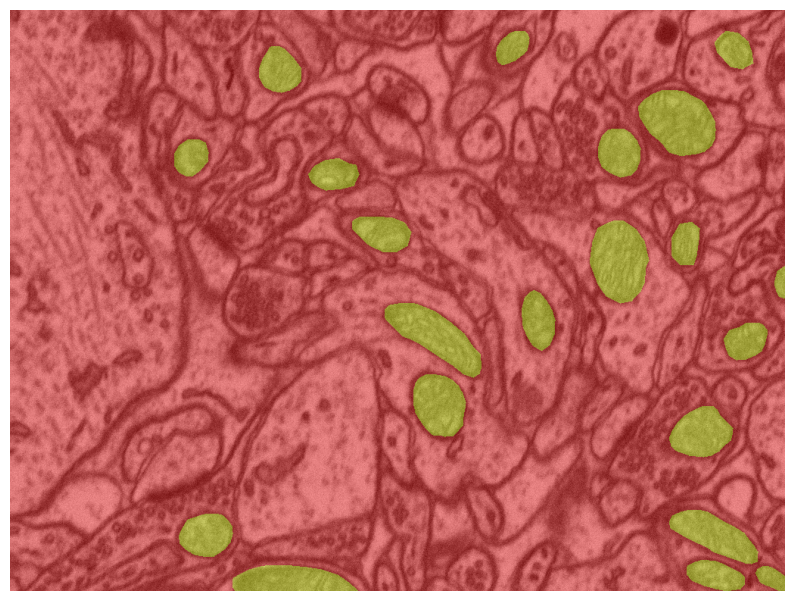

In [5]:
# image overlay
plt.figure(figsize=(10, 10))

plt.imshow(img, cmap='gray')
plt.imshow(mask, cmap='autumn', alpha=0.4)

plt.axis('off')
plt.show()

## Define UNet

### The Model

In [6]:
import torch
import torch.nn as nn

class UNet(nn.Module):
  def __init__(self, IMG_HEIGHT:int, IMG_WIDTH:int, IMG_CHANNELS:int) -> None:
    super().__init__()
    self.c1 = nn.Sequential(
        nn.Conv2d(IMG_CHANNELS, 16, 3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Conv2d(16, 16, 3, padding=1),
        nn.ReLU()
    )

    self.pool = nn.MaxPool2d(2)

    self.c2 = nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Conv2d(32, 32, kernel_size=3, padding=1),
        nn.ReLU(),
    )

    self.c3 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.ReLU(),
    )

    self.c4 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Conv2d(128, 128, kernel_size=3, padding=1),
        nn.ReLU()
    )

    self.c5 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Conv2d(256, 256, kernel_size=3, padding=1),
        nn.ReLU()
    )

    # expansive path
    self.u6 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)

    self.c6 = nn.Sequential(
        nn.Conv2d(256, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Conv2d(128, 128, kernel_size=3, padding=1),
        nn.ReLU()
    )

    self.u7 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)

    self.c7 = nn.Sequential(
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.ReLU()
    )

    self.u8 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)

    self.c8 = nn.Sequential(
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Conv2d(32, 32, kernel_size=3, padding=1),
        nn.ReLU()
    )

    self.u9 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)

    self.c9 = nn.Sequential(
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Conv2d(16, 16, kernel_size=3, padding=1),
        nn.ReLU()
    )

    self.out = nn.Sequential(
        nn.Conv2d(16, 1, kernel_size=1),
        nn.Sigmoid()
    )

    # weight initialisation
    for m in self.modules():
      if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
          nn.init.kaiming_normal_(
              m.weight,
              mode='fan_in',
              nonlinearity='relu'
          )

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    # contraction
    c1 = self.c1(x)
    p1 = self.pool(c1)

    c2 = self.c2(p1)
    p2 = self.pool(c2)

    c3 = self.c3(p2)
    p3 = self.pool(c3)

    c4 = self.c4(p3)
    p4 = self.pool(c4)

    c5 = self.c5(p4)

    # expansion
    u6 = self.u6(c5)
    u6 = torch.cat([u6, c4], dim=1)
    c6 = self.c6(u6)

    u7 = self.u7(c6)
    u7 = torch.cat([u7, c3], dim=1)
    c7 = self.c7(u7)

    u8 = self.u8(c7)
    u8 = torch.cat([u8, c2], dim=1)
    c8 = self.c8(u8)

    u9 = self.u9(c8)
    u9 = torch.cat([u9, c1], dim=1)
    c9 = self.c9(u9)

    return self.out(c9)

In [7]:
# sanity check
model = UNet(256, 256, 3)

x = torch.randn(2,3,256, 256)

output = model(x)

print(output.shape)

torch.Size([2, 1, 256, 256])


## Training

### preprocessing

In [8]:
import os
import cv2
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

image_directory = "/content/dataset/images"
mask_directory = "/content/dataset/masks"

SIZE = 256
image_dataset = []
mask_dataset = []

images = os.listdir(image_directory)
for i, image_name in enumerate(images):
  if (image_name.split('.')[1] == 'png'):
    image_path = os.path.join(image_directory, image_name)
    image = cv2.imread(image_path, 0)
    if image is not None:
      image = Image.fromarray(image)
      image = image.resize((SIZE, SIZE))
      image_dataset.append(np.array(image))

masks = os.listdir(mask_directory)
for i, mask_name in enumerate(masks):
  if (mask_name.split('.')[1] == 'png'):
    mask_path = os.path.join(mask_directory, mask_name)
    mask = cv2.imread(mask_path, 0)
    if mask is not None:
      mask = Image.fromarray(mask)
      mask = mask.resize((SIZE, SIZE))
      mask_dataset.append(np.array(mask))

# convert to float numpy array and normalize
image_dataset = np.expand_dims(np.array(image_dataset, dtype=np.float32) / 255.0, axis=3)
image_dataset = torch.from_numpy(image_dataset).permute(0, 3, 1, 2)
# rescale masks to 0-1
mask_dataset = np.expand_dims(np.array(mask_dataset, dtype=np.float32), axis=3) / 255.0
mask_dataset = torch.from_numpy(mask_dataset).permute(0, 3, 1, 2)


### Define and train

In [9]:
IMG_CHANNELS, IMG_HEIGHT, IMG_WIDTH = image_dataset.shape[1], image_dataset.shape[2], image_dataset.shape[3]
model = UNet(IMG_HEIGHT=IMG_HEIGHT, IMG_WIDTH=IMG_WIDTH, IMG_CHANNELS=IMG_CHANNELS)

In [10]:
from sklearn.model_selection import train_test_split

# First split: 90% development, 10% testing
X_temp, X_test, y_temp, y_test = train_test_split(
    image_dataset,
    mask_dataset,
    test_size=0.1,
    random_state=100
)

# Second split: 80% training, 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=1/9,
    random_state=100
)

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size = 8,
    shuffle=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

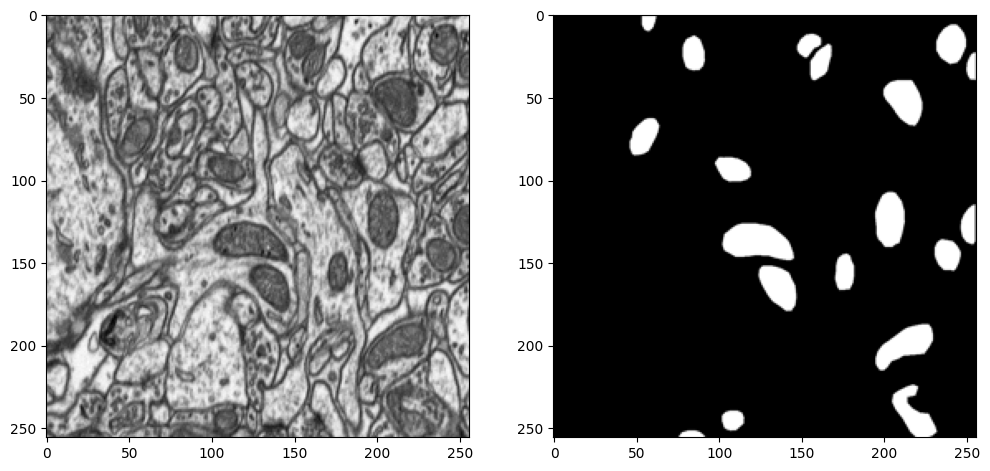

In [11]:
#  sanity check
import random
image_number = random.randint(0, len(X_train) - 1)
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(np.reshape(X_train[image_number], (256, 256)), cmap='gray')
plt.subplot(122)
plt.imshow(np.reshape(y_train[image_number], (256, 256)), cmap='gray')
plt.show()

In [12]:
# define loss
def dice_loss(pred, target, smooth=1e-6):
  pred = pred.flatten(1)
  target = target.flatten(1)

  # calculate intersection
  intersection = (pred * target).sum(dim=1)

  dice = (2.0 * intersection + smooth)/ (pred.sum(dim=1) + target.sum(dim=1) + smooth)

  return 1 - dice.mean()

bce = nn.BCELoss()

def criterion(pred, target):
  return bce(pred, target) + dice_loss(pred, target)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 1e-4
)

In [13]:
# training loop
from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

model = model.to(device)

EPOCHS = 100
best_val_loss = float('inf')


for epoch in tqdm(range(EPOCHS)):
  # training
  model.train()
  train_loss = 0.0

  for images, masks in train_loader:

    images, masks = images.to(device), masks.to(device)

    # forward
    pred = model(images)

    # calculate loss
    loss = criterion(pred, masks)

    # clear previous grads
    optimizer.zero_grad()

    # backprop
    loss.backward()

    # update steps
    optimizer.step()

    train_loss += loss.item()

  train_loss /= len(train_loader)

  # validation
  model.eval()
  val_loss = 0.0

  with torch.no_grad():
    for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            predictions = model(images)
            loss = criterion(predictions, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    # save best model
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      torch.save(model.state_dict(), "best_unet.pt")

      print(f"Early stopping triggered at epoch {epoch + 1}")
      print(f"Train Loss: {train_loss:.4f}")
      print(f"Best Val Loss: {best_val_loss:.4f}")

cuda


  1%|          | 1/100 [00:02<04:55,  2.98s/it]

Early stopping triggered at epoch 1
Train Loss: 1.2603
Best Val Loss: 1.2082


  2%|▏         | 2/100 [00:04<03:12,  1.97s/it]

Early stopping triggered at epoch 2
Train Loss: 1.1499
Best Val Loss: 1.1442


  3%|▎         | 3/100 [00:05<02:39,  1.65s/it]

... (68 outputs left out)

Early stopping triggered at epoch 94
Train Loss: 0.1088
Best Val Loss: 0.1014


 95%|█████████▌| 95/100 [02:14<00:07,  1.42s/it]

Early stopping triggered at epoch 95
Train Loss: 0.1068
Best Val Loss: 0.0983


100%|██████████| 100/100 [02:21<00:00,  1.42s/it]


## Testing

In [14]:
model.load_state_dict(
    torch.load("best_unet.pt", map_location=device)
)

model.eval()

dice_scores = []
iou_scores = []
precision_scores = []
recall_scores = []

smooth = 1e-6

model.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Forward pass
        predictions = model(images)

        # Convert probabilities into binary masks
        predictions = (predictions > 0.5).float()
        masks = (masks > 0.5).float()

        # Flatten each image separately
        predictions = predictions.flatten(1)
        masks = masks.flatten(1)

        # Calculate TP, FP, FN
        TP = (predictions * masks).sum(dim=1)
        FP = (predictions * (1 - masks)).sum(dim=1)
        FN = ((1 - predictions) * masks).sum(dim=1)

        # Metrics
        dice = (2 * TP + smooth) / (2 * TP + FP + FN + smooth)

        iou = (TP + smooth) / (TP + FP + FN + smooth)

        precision = (TP + smooth) / (TP + FP + smooth)

        recall = (TP + smooth) / (TP + FN + smooth)

        dice_scores.extend(dice.cpu().tolist())
        iou_scores.extend(iou.cpu().tolist())
        precision_scores.extend(precision.cpu().tolist())
        recall_scores.extend(recall.cpu().tolist())

In [16]:
import pandas as pd
metrics_data = {
    'Metric': ['Dice Coefficient', 'Intersection over Union (IoU)', 'Precision', 'Recall'],
    'Score': [
        np.mean(dice_scores),
        np.mean(iou_scores),
        np.mean(precision_scores),
        np.mean(recall_scores)
    ]
}

df_metrics = pd.DataFrame(metrics_data)
display(df_metrics)

,Metric,Score
0,Dice Coefficient,0.944638
1,Intersection over Union (IoU),0.895321
2,Precision,0.915148
3,Recall,0.976492


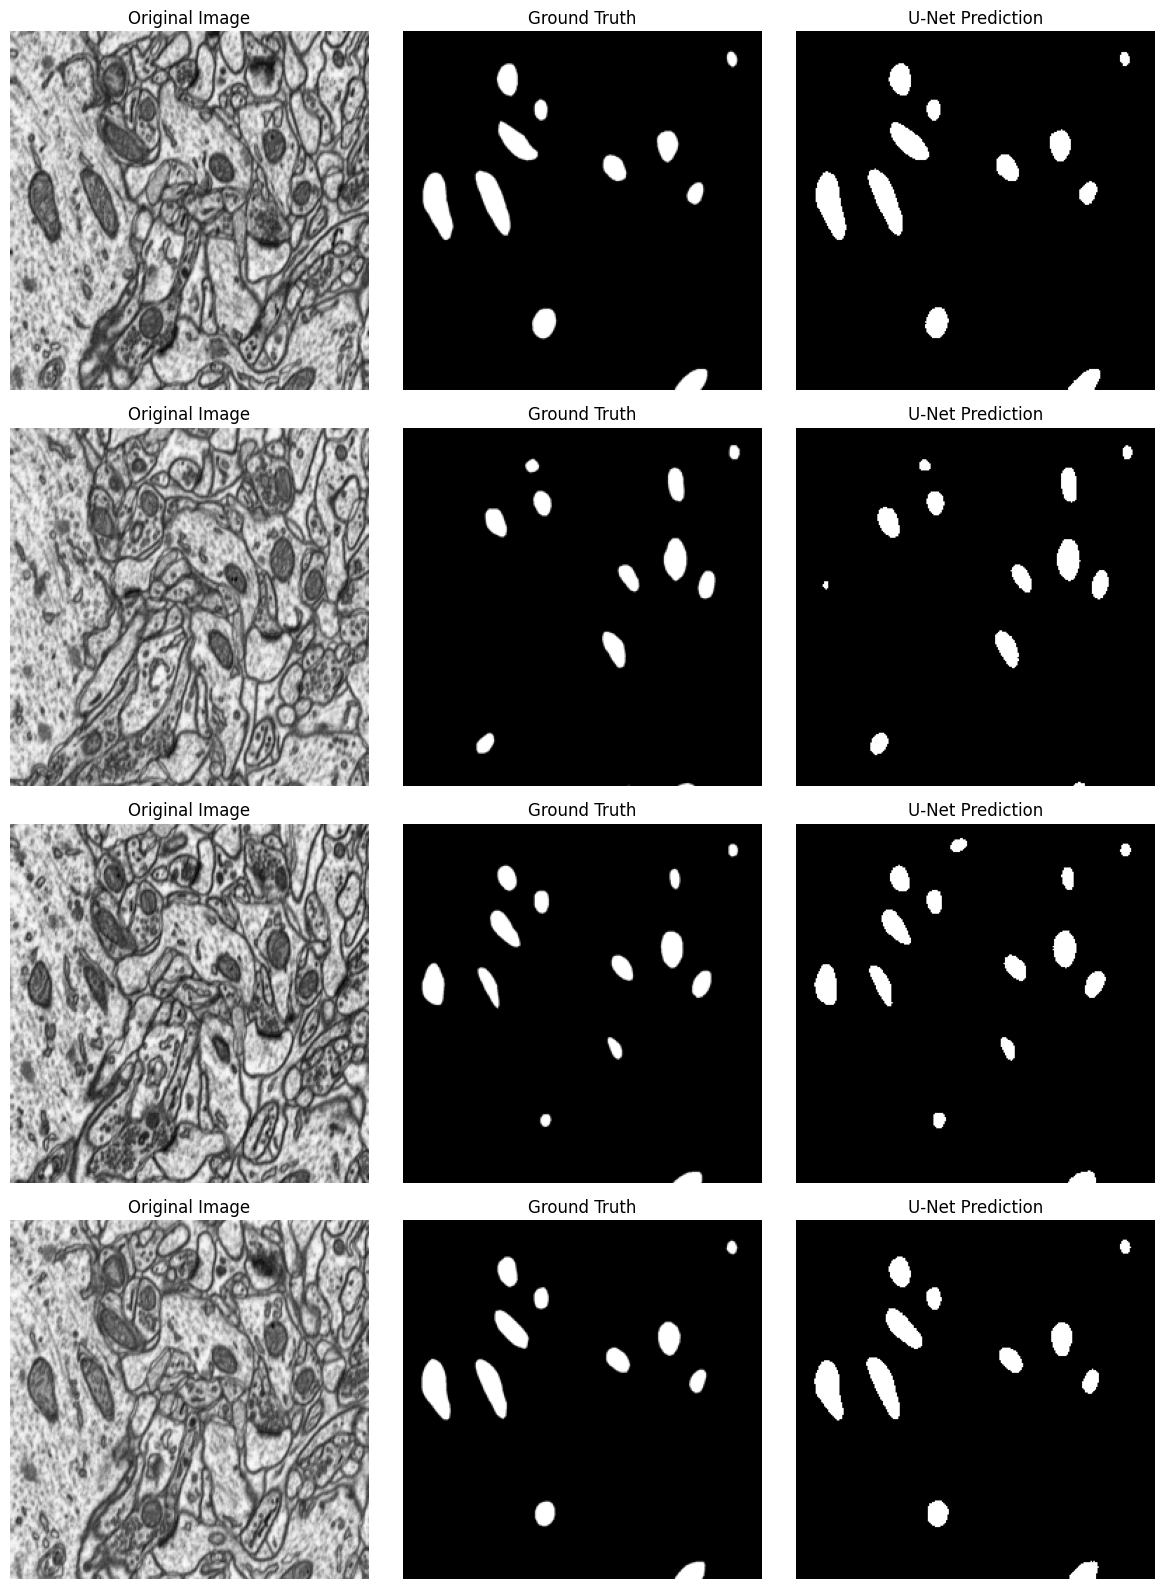

In [17]:
import matplotlib.pyplot as plt

model.eval()

images, masks = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
    predictions = model(images)

predictions = (predictions > 0.5).float()

# Display first 4 samples
fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):

    axes[i, 0].imshow(
        images[i].cpu().squeeze(), cmap='gray'
    )
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        masks[i].squeeze(), cmap='gray'
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        predictions[i].cpu().squeeze(), cmap='gray'
    )
    axes[i, 2].set_title("U-Net Prediction")

    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()